# Backward heat equation in 2-D — Fourier truncation regularisation
**Reproduction of:** H. T. Nguyen, *Stability and regularization for 2-D backward heat conduction equation*,
Math. Reports **17(67)**, 1 (2015), 1–23.

This notebook is a guided tour for a live presentation. Every number is computed by the library in
`src/backward_heat`, the same code used by `experiments/run_all.py`.

**Problem (1):** find $u(\cdot,\cdot,0)$ from
$$u_t-\Delta u=f \text{ in } (0,\pi)^2\times(0,T),\qquad u=0 \text{ on the boundary},\qquad u(\cdot,\cdot,T)=g.$$

In [1]:
%matplotlib inline
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
os.environ['BACKWARD_HEAT_INTERACTIVE'] = '1'   # keep the inline backend
sys.path.insert(0, '../src')
from backward_heat import Grid, PaperExample, SeparableExponentialSource, add_paper_noise, make_rng, reconstruct
from backward_heat import visualization as viz
from backward_heat.metrics import paper_error, relative_l2_error
from backward_heat.regularization import cutoff_rules
viz.apply_style()
grid, ex = Grid(128), PaperExample()          # 129 x 129 nodes, T = 1, K = 15 (paper, Section 4)
src = SeparableExponentialSource(ex.f_spatial_coefficients(grid), ex.time_rate())
X = grid.x

## 1. Why the problem is ill-posed
Each sine mode evolves as $u_{mn}(t)=e^{(T-t)\lambda_{mn}}g_{mn}-\int_t^T e^{(s-t)\lambda_{mn}}f_{mn}(s)\,ds$ with $\lambda_{mn}=m^2+n^2$ (eq. 6).
A data error $\delta$ in mode $(m,n)$ is multiplied by $e^{(T-t)\lambda_{mn}}$:

In [2]:
lam = np.array([2, 5, 10, 20, 50, 100, 200])
pd.DataFrame({'lambda = m^2+n^2': lam, 'amplification e^{lambda} (t=0, T=1)': np.exp(lam.astype(float))})

,lambda = m^2+n^2,"amplification e^{lambda} (t=0, T=1)"
0,2,7.389056e+00
1,5,1.484132e+02
2,10,2.202647e+04
3,20,4.851652e+08
4,50,5.184706e+21
5,100,2.688117e+43
6,200,7.225974e+86


## 2. The method: keep only $m^2+n^2\le M_\varepsilon$ (eq. 12)
The four a-priori cut-off rules reproduce **Table 1** exactly. This requires $r=2$ in Theorem 6, a value the paper does not state.
It also requires the square-root form of Theorem 7, which is the form in the theorem's statement, not in its proof.

In [3]:
rules = cutoff_rules()
pd.DataFrame({r: {f'eps=1e-{k}': round(fn(10.0**-k, 1.0), 4) for k in (3, 5, 7)} for r, fn in rules.items()}).T

,eps=1e-3,eps=1e-5,eps=1e-7
M1,4.8399,8.9862,13.2780
M2,3.4539,5.7565,8.0590
M3,8.7052,13.8731,18.8378
M4,2.1460,2.7704,3.2780


## 3. One reconstruction, step by step (ε = 1e-5, t = 0, rule M³)

actual ||g_eps - g||_L2 = 5.78e-06 (<= eps)   M = 13.873   modes kept = 8
paper metric = 1.4255e-01   (Table 2 prints 1.424E-01)


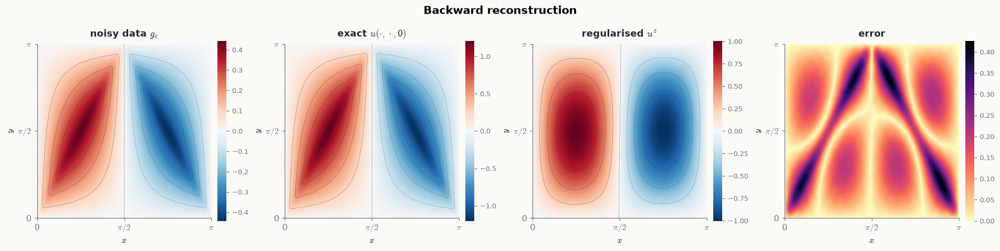

In [4]:
eps = 1e-5
noisy = add_paper_noise(ex.g_grid(grid), grid, eps, make_rng(2015))      # g_eps = g + (eps/pi) rand()
M = rules['M3'](eps, 1.0)
res = reconstruct(noisy.values, 0.0, M, grid, 1.0, src)
exact = ex.u_grid(grid, 0.0)
print(f'actual ||g_eps - g||_L2 = {noisy.l2_norm:.2e} (<= eps)   M = {M:.3f}   modes kept = {res.n_modes}')
print(f'paper metric = {paper_error(exact, res.u):.4e}   (Table 2 prints 1.424E-01)')
fig = viz.field_panels(X, [noisy.values, exact, res.u, np.abs(exact - res.u)],
                       ['noisy data $g_\\varepsilon$', 'exact $u(\\cdot,\\cdot,0)$', 'regularised $u^\\varepsilon$', 'error'],
                       'Backward reconstruction', error_last=True, shared_scale=False); plt.show()

## 4. Table 2 reproduced
The paper's "$L^2$ error" is in fact the RMS over the $129^2$ grid nodes. That metric gives exactly 0.5161 when no mode is kept and 0.1423 when only $k=1$ is kept.

In [5]:
t2 = pd.read_csv('../results/tables/table2_long.csv')
print('median |rel. diff| vs. paper:', t2.rel_diff.abs().median())
t2[t2.t.isin([0.0, 0.5, 0.9])].pivot_table(index='t', columns=['eps', 'rule'], values='ours').style.format('{:.3e}')

median |rel. diff| vs. paper: 5.159642902155842e-05


## 5. Published figures, reproduced

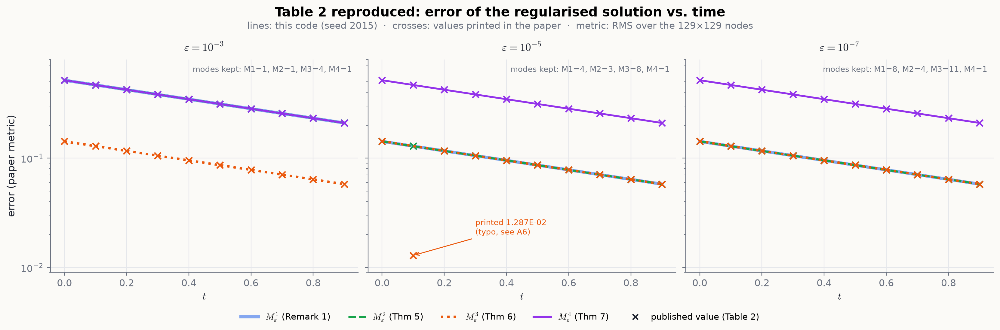

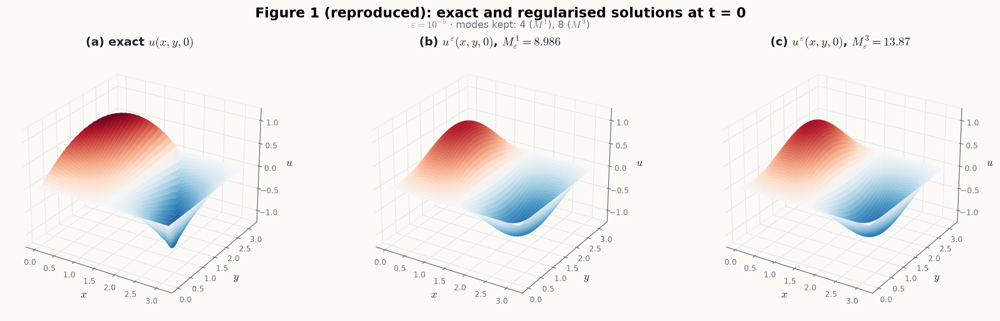

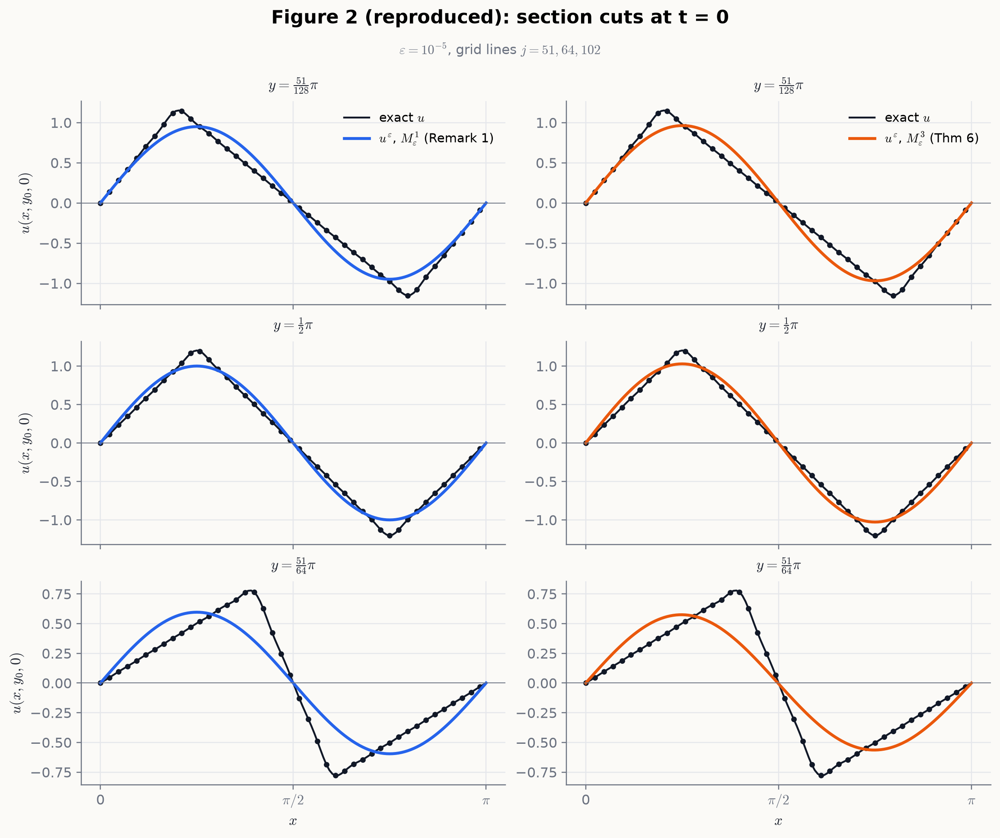

In [6]:
from IPython.display import Image, display
for name in ['table2_reproduction', 'figure1_surfaces', 'figure2_section_cuts']:
    display(Image(f'../results/figures/{name}.png', width=950))

## 6. Beyond the paper: the stability–accuracy trade-off (supplementary)
The paper concludes that "the bigger $M_\varepsilon$, the better". That holds only for $M<20$. Beyond that,
amplified noise and even float64 rounding dominate the error:

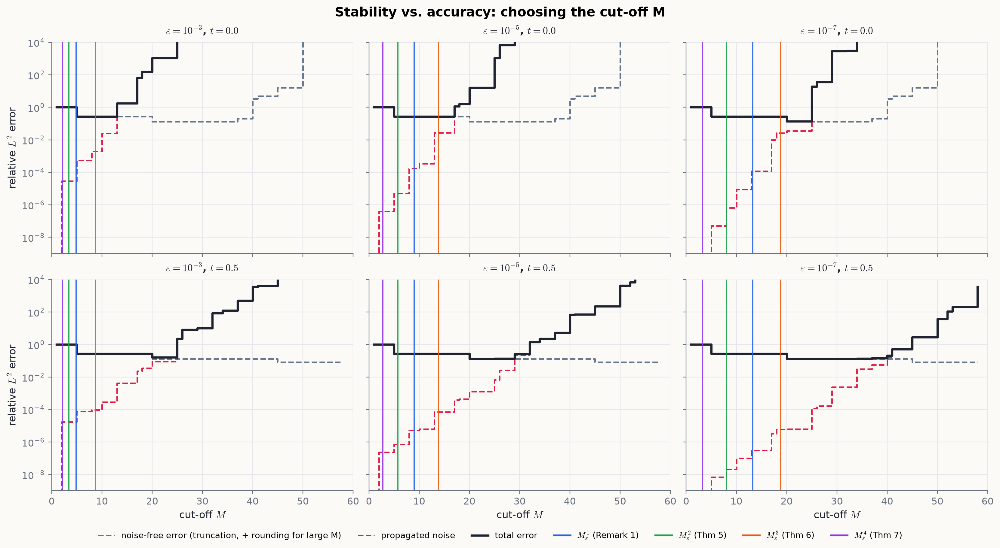

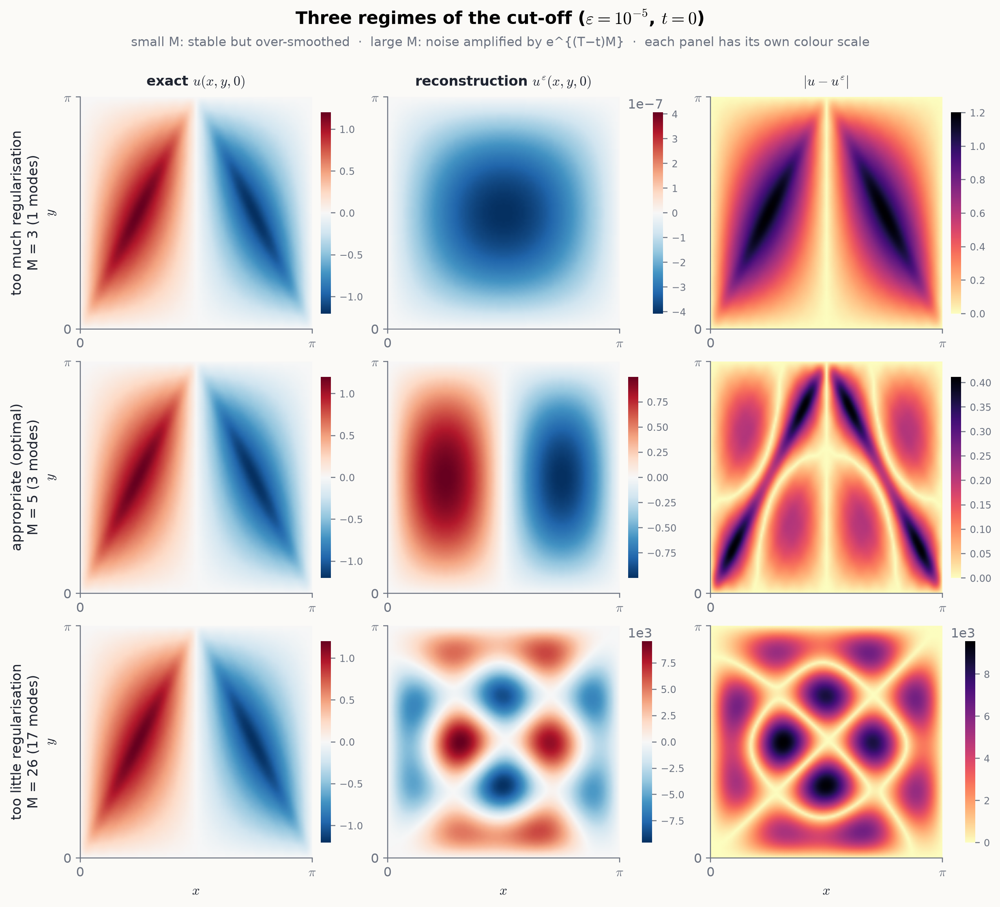

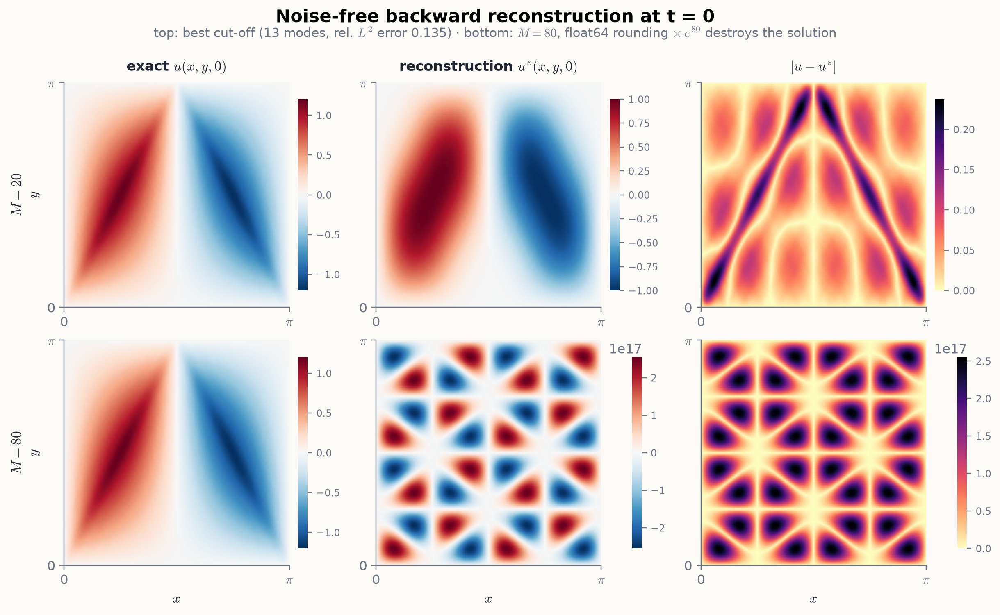

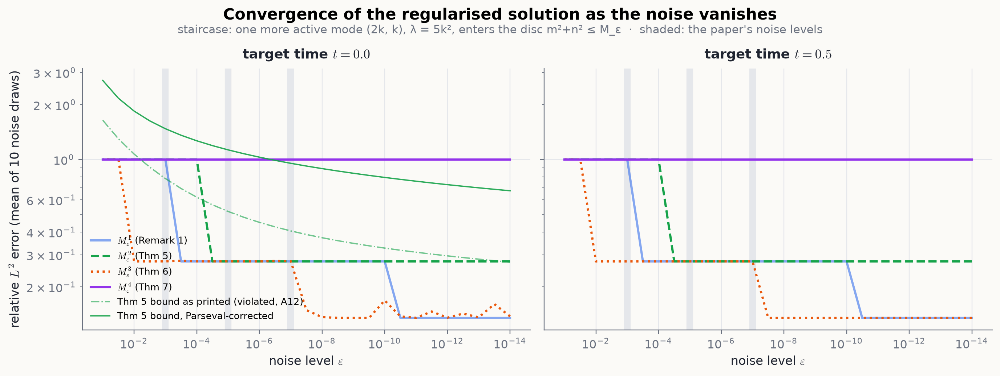

In [7]:
for name in ['exp04_tradeoff', 'exp04_three_regimes', 'exp02_noiseless_reconstruction', 'exp03_error_vs_noise_level']:
    display(Image(f'../results/figures/{name}.png', width=950))

## 7. Try it live
Run `python demo.py` from the project root for an interactive window with sliders for ε, t and M.